# 04.2 SVM: búsqueda de hiperparámetros (experimento 2)

- Entrada: `data/processed/dev_features.csv` (salida del notebook 03)
- Salida: `best_params/`, `trials/` y `figures/` de este modelo (cada archivo está explicado en el `README.md` del experimento 1)

Es la misma búsqueda del experimento 1 con otras variables: los mejores ajustes dependen de las variables de entrada, así que hay que repetirla. Qué cambia y por qué está explicado en el notebook de modelado del experimento 2.

Instrucciones:

- Misma validación que en el experimento 1: 5 grupos separados por animal, semilla `SEED` y `N_TRIALS` pruebas.
- Nombre de los archivos que se generan: `svm_clf` y `svm_reg`.
- No usar `test`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, SVR

from config import SEED
from features import CAT_LOW, CAT_HIGH, BINARY, NUMERIC, NUMERIC_LOG, add_age_log, build_preprocessor
from tuning import tune

N_TRIALS = 20

data = add_age_log(pd.read_csv("../../data/processed/dev_features.csv"))
groups = data["animal_id_intake"]

/Users/klorenzoe/Documents/Personal/MUCSI/ML/mucsi-ml-animal-shelter-project/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Inputs

Variables del experimento 2 para SVM. Frente al experimento 1 se agregan raza, color y ciudad (`CAT_HIGH`) y, en regresión, la edad se usa en logaritmo (`age_log`) en lugar de `age_days`.

In [2]:
FEATURES_EXP2_CLF = CAT_LOW + CAT_HIGH + BINARY + NUMERIC
FEATURES_EXP2_REG = CAT_LOW + CAT_HIGH + BINARY + [c for c in NUMERIC if c != "age_days"] + NUMERIC_LOG

print("El experimento 2 usa estas variables:")
print("Clasificación:", FEATURES_EXP2_CLF)
print("Regresión:", FEATURES_EXP2_REG)

# Clasificación: todas las filas
y_clf = data["y_outcome"]

# Regresión: solo adoptados
adopted = data["y_outcome"] == "Adoption"
y_reg = data.loc[adopted, "y_log_days"]
groups_reg = groups[adopted]

El experimento 2 usa estas variables:
Clasificación: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']
Regresión: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'prior_stays', 'hour', 'month', 't_months', 'age_log']


## Qué se ajusta

| Ajuste | Qué hace | Rango probado |
|---|---|---|
| `C` | Qué tan estricto es el modelo con los errores. Bajo: más flexible y simple. Alto: se pega más a los datos de entrenamiento. | 0,01 a 100 |
| `gamma` | Qué tan cerca deben estar dos animales para considerarse parecidos. Bajo: modelo más suave. Alto: se fija en detalles y puede aprenderse los datos de memoria. | 0,0001 a 1 |
| `class_weight` | Solo en clasificación. `balanced` da más peso a las clases pequeñas, `None` trata a todas igual. | `None` o `balanced` |
| `epsilon` | Solo en regresión. Diferencia que el modelo tolera sin contarla como error. | **0,05 a 1** (en el experimento 1 era 0,01 a 0,5) |

`C`, `gamma` y `epsilon` se prueban en escala logarítmica: así se exploran por igual valores pequeños y grandes.

Con raza, color y ciudad el modelo tiene más columnas y cada prueba tarda más que en el experimento 1.

## 1. Clasificación

Objetivo: `y_outcome` (5 clases), con todas las filas. Se elige por macro-F1. La búsqueda usa el 20 % de los animales para que cada prueba sea rápida.

Búsqueda de SVM (clasificación): 20 pruebas con 12,729 filas y 11,512 animales.
Prueba 1/20: resultado 0.169 | mejor hasta ahora 0.169
Prueba 2/20: resultado 0.025 | mejor hasta ahora 0.169
Prueba 3/20: resultado 0.497 | mejor hasta ahora 0.497
Prueba 4/20: resultado 0.431 | mejor hasta ahora 0.497
Prueba 5/20: resultado 0.417 | mejor hasta ahora 0.497
Prueba 6/20: resultado 0.412 | mejor hasta ahora 0.497
Prueba 7/20: resultado 0.497 | mejor hasta ahora 0.497
Prueba 8/20: resultado 0.279 | mejor hasta ahora 0.497
Prueba 9/20: resultado 0.120 | mejor hasta ahora 0.497
Prueba 10/20: resultado 0.120 | mejor hasta ahora 0.497
Prueba 11/20: resultado 0.422 | mejor hasta ahora 0.497
Prueba 12/20: resultado 0.500 | mejor hasta ahora 0.500
Prueba 13/20: resultado 0.481 | mejor hasta ahora 0.500
Prueba 14/20: resultado 0.480 | mejor hasta ahora 0.500
Prueba 15/20: resultado 0.298 | mejor hasta ahora 0.500
Prueba 16/20: resultado 0.500 | mejor hasta ahora 0.500
Prueba 17/20: resultado 0.480 | m

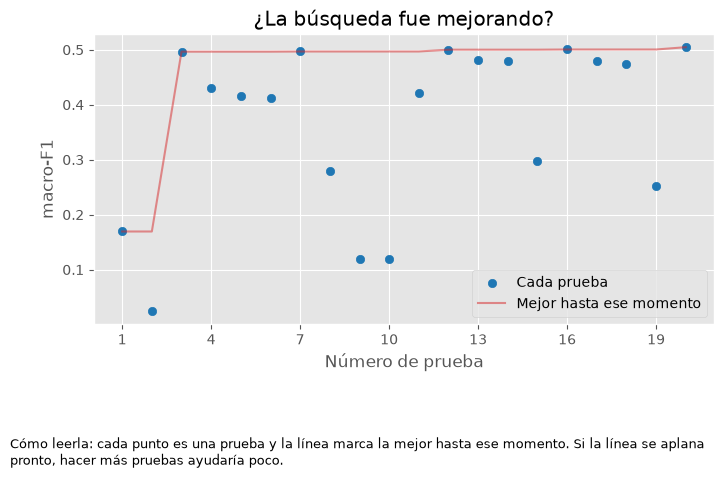

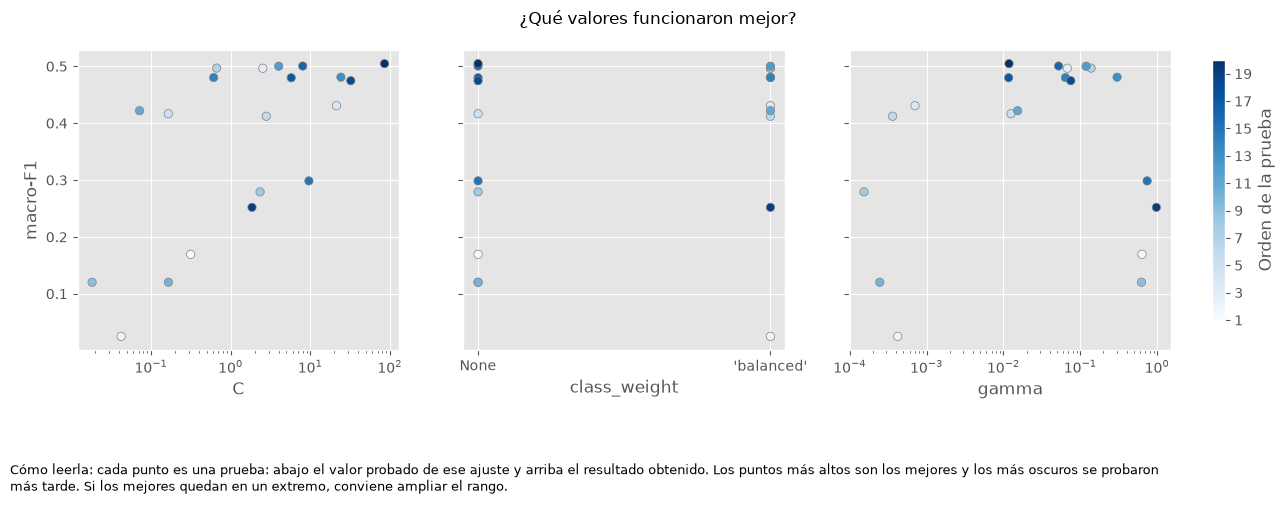

In [3]:
def make_pipe_clf(params):
    return Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP2_CLF)),
                     ("model", SVC(**params))])

def space_clf(trial):
    return {"C": trial.suggest_float("C", 1e-2, 1e2, log=True),
            "gamma": trial.suggest_float("gamma", 1e-4, 1, log=True),
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"])}

study_clf = tune(
    "svm_clf", make_pipe_clf, space_clf, data[FEATURES_EXP2_CLF], y_clf, groups,
    scoring="f1_macro", features=FEATURES_EXP2_CLF, model_label="SVM", task_label="clasificación",
    params_help={"C": "Qué tan estricto es el modelo con los errores (alto = más estricto).",
                 "gamma": "Qué tan cerca deben estar dos animales para considerarse parecidos (alto = más detalle).",
                 "class_weight": "balanced da más peso a las clases pequeñas."},
    n_trials=N_TRIALS, subsample=0.2)

## 2. Regresión

Objetivo: `y_log_days`, solo con las filas donde `y_outcome == "Adoption"`. Se elige por R² en log. Usa todos los adoptados.

Búsqueda de SVM (regresión): 20 pruebas con 27,073 filas y 24,720 animales.
Prueba 1/20: resultado 0.177 | mejor hasta ahora 0.177
Prueba 2/20: resultado 0.185 | mejor hasta ahora 0.185
Prueba 3/20: resultado 0.144 | mejor hasta ahora 0.185
Prueba 4/20: resultado 0.176 | mejor hasta ahora 0.185
Prueba 5/20: resultado 0.252 | mejor hasta ahora 0.252
Prueba 6/20: resultado 0.113 | mejor hasta ahora 0.252
Prueba 7/20: resultado 0.200 | mejor hasta ahora 0.252
Prueba 8/20: resultado 0.083 | mejor hasta ahora 0.252
Prueba 9/20: resultado 0.342 | mejor hasta ahora 0.342
Prueba 10/20: resultado 0.312 | mejor hasta ahora 0.342
Prueba 11/20: resultado 0.268 | mejor hasta ahora 0.342
Prueba 12/20: resultado 0.318 | mejor hasta ahora 0.342
Prueba 13/20: resultado 0.303 | mejor hasta ahora 0.342
Prueba 14/20: resultado 0.321 | mejor hasta ahora 0.342
Prueba 15/20: resultado 0.326 | mejor hasta ahora 0.342
Prueba 16/20: resultado 0.342 | mejor hasta ahora 0.342
Prueba 17/20: resultado 0.311 | mejor

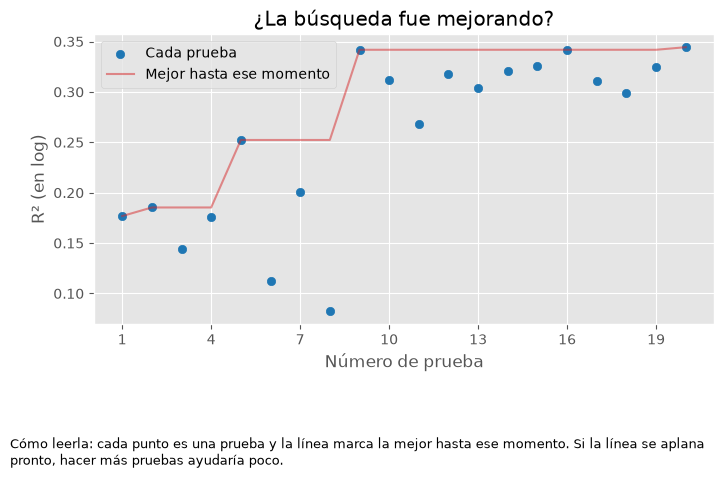

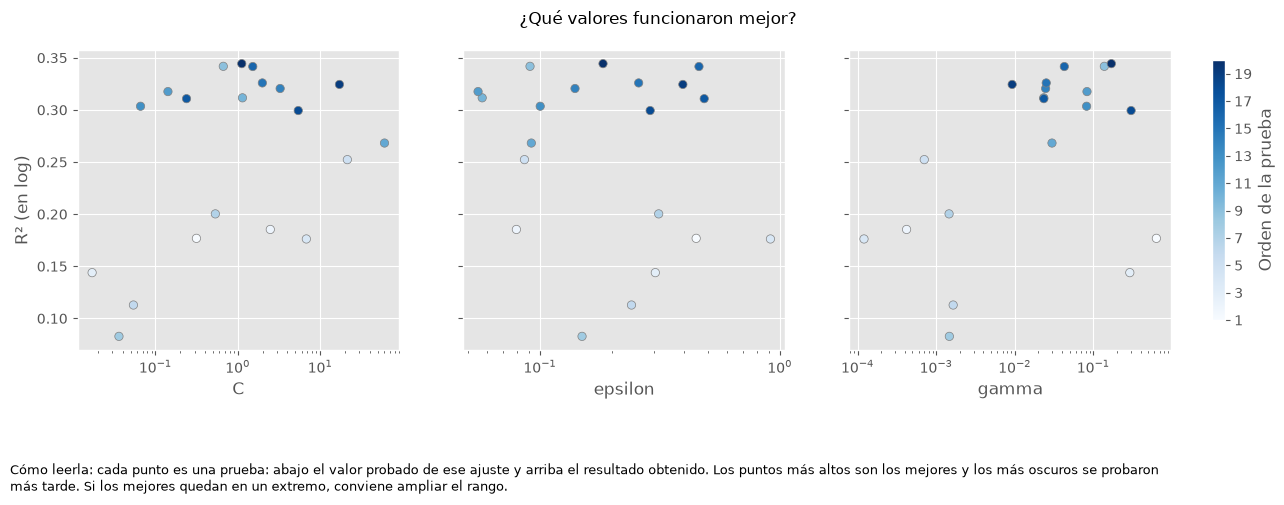

In [4]:
def make_pipe_reg(params):
    return Pipeline([("prep", build_preprocessor(numeric=NUMERIC + NUMERIC_LOG, columns=FEATURES_EXP2_REG)),
                     ("model", SVR(**params))])

def space_reg(trial):
    return {"C": trial.suggest_float("C", 1e-2, 1e2, log=True),
            "gamma": trial.suggest_float("gamma", 1e-4, 1, log=True),
            "epsilon": trial.suggest_float("epsilon", 5e-2, 1.0, log=True)}

study_reg = tune(
    "svm_reg", make_pipe_reg, space_reg, data.loc[adopted, FEATURES_EXP2_REG], y_reg, groups_reg,
    scoring="r2", features=FEATURES_EXP2_REG, model_label="SVM", task_label="regresión",
    params_help={"C": "Qué tan estricto es el modelo con los errores (alto = más estricto).",
                 "gamma": "Qué tan cerca deben estar dos animales para considerarse parecidos (alto = más detalle).",
                 "epsilon": "Diferencia que el modelo tolera sin contarla como error."},
    n_trials=N_TRIALS)